In [21]:
import torch 
import torch.nn as nn 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\USER\Desktop\AI_for_Cosmology\.venv\Scripts\python.exe -m pip install --upgrade pip


### Baseline Neural Network of ΛCDM Expansion History

In this section, a conventional feed-forward neural network is employed as a baseline model to approximate the cosmological expansion  
history H(z) in a flat ΛCDM cosmological model. Synthetic target data have been generated on the analytical relationship
$$
H(z) = \sqrt{\Omega_m(1+z)^3 + (1-\Omega_m)}
$$
where $ \Omega_m = 0.3$

<br><br>

In [3]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)

omega_m = 0.3
class ΛCDM_nn(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z
model_nn = ΛCDM_nn()
optimizer_nn = torch.optim.Adam(model_nn.parameters(), lr=0.01)
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))

for epoch in range(1000):
    H_pred = model_nn(z)
    loss_data_nn = torch.mean((H_true - H_pred)**2)
    optimizer_nn.zero_grad()
    loss_data_nn.backward()
    optimizer_nn.step()
    if epoch %100 ==0:
        print(epoch, loss_data_nn.item())

0 2.3639535903930664
100 0.013560919091105461
200 0.008839094080030918
300 0.005855068098753691
400 0.0037093982100486755
500 0.002053384203463793
600 0.0008979974081739783
700 0.0003048685030080378
800 9.96821909211576e-05
900 4.9195936298929155e-05


In [4]:
print('MSE:', loss_data_nn.item())

MSE: 3.8198202673811466e-05


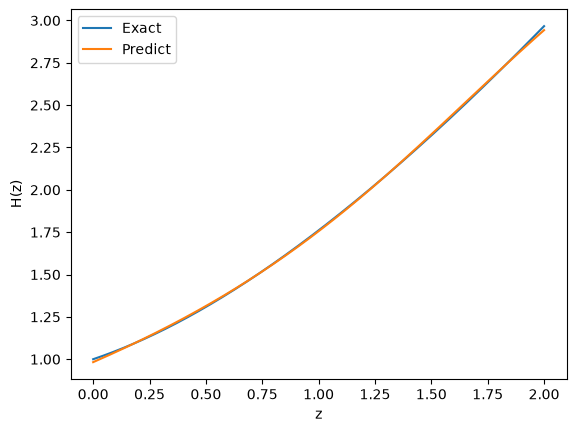

In [5]:
plt.plot(z.numpy(), H_true.numpy(), label='Exact')
plt.plot(z.numpy(), H_pred.detach().numpy(), label='Predict')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.legend()

plt.show()

- At this stage, no physical differential equations or cosmological parameter inferences are incorporated into the loss function. The aim of this experiment  
is to establish a purely data-driven baseline against which the "Physics-Informed Neural Network" to be employed later—can be compared.

- Following training, the predicted expansion history is compared with the analytical solution of the ΛCDM model. The close agreement between these two   curves demonstrates that the neural network is capable of approximating the system's expansion history using "clean" (noise-free) synthetic data.

<br><br>

### Baseline Neural Network with Noise Data

In this section, the conventional neural network model is evaluated in the presence of observational noise. Starting with the ΛCDM expansion history, Gaussian noise is added to generate synthetic observations:
$$
H_{obs}(z)=H_{true}(z)+ϵ,
$$
where $ϵ∼\mathcal{N}(0,σ2).$ A noise standard deviation of $\sigma=0.05$ is used in this experiment.   
The neural network is trained only against the noisy observations using the mean squared error.
<br><br>

In [6]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)

omega_m = 0.3
class ΛCDM_nn_noise(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z
model_nn_noise = ΛCDM_nn_noise()
optimizer_nn_noise = torch.optim.Adam(model_nn_noise.parameters(), lr=0.01)
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std *torch.randn_like(H_true)
H_obs = H_true + noise

for epoch in range(1000):
    H_pred = model_nn_noise(z)
    loss_data_nn_noise = torch.mean((H_obs - H_pred)**2)
    optimizer_nn_noise.zero_grad()
    loss_data_nn_noise.backward()
    optimizer_nn_noise.step()
    if epoch %100 ==0:
        print(epoch, loss_data_nn_noise.item())

0 2.3666396141052246
100 0.016311433166265488
200 0.011481515131890774
300 0.00841858796775341
400 0.006199133116751909
500 0.004470651503652334
600 0.0032670816872268915
700 0.0026609033811837435
800 0.002458080416545272
900 0.0024101787712424994


In [7]:
mse_obs = torch.mean((H_pred - H_obs)**2)
mse_true = torch.mean((H_pred - H_true)**2)
print("MSE vs observed:", mse_obs.item())
print("MSE vs true:", mse_true.item())

MSE vs observed: 0.0024001593701541424
MSE vs true: 3.740055035450496e-05


- In this scenario, the analytical solution $H_{true}(z)$ is preserved separately and is not used as a training target. This enables an independent evaluation of the final model against the underlying noise-free solution.

- When faced with noisy observations, the trained network achieves an MSE of approximately $2.4\times10^{-3}$, whereas its MSE relative to the underlying noise-free solution is approximately $3.7\times10^{-5}$.

- This result indicates that the neural network does not reproduce all the random fluctuations present in the noisy data; instead, it learns a relatively smooth approximation of the underlying expansion history. This experiment provides a crucial basis for evaluating whether imposing physical constraints via a Physics-Informed Neural Network (PINN) can further enhance robustness against noisy data.
<br><br>

### Physics Informed Neural Network(PINN) for ΛCDM Expansion History


- In this section, a Physics-Informed Neural Network (PINN) is developed to model the cosmic expansion history, $H(z)$, incorporating the dynamics of the $\Lambda$CDM model (as the baseline model) into the training process.

- Unlike conventional neural networks, the PINN does not rely solely on a data-fitting loss function; instead, the training objective comprises a combination of the physical residual, initial conditions, and the data-fitting term.

- By differentiating the Hubble parameters, we obtain

$$
2H\frac{dH}{dz} -3\Omega_m (1+z)^2=0
$$

- The neural network predicts $H_\theta(z)$, and automatic differentiation is used to compute $dH_\theta/dz$.
  <br><br>

In [8]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)
omega_m = 0.3
class ΛCDM_pinn(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

model_pinn = ΛCDM_pinn()
optimizer_pinn = torch.optim.Adam(model_pinn.parameters(), lr =0.01)
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m)).detach()
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 2.0

for epoch in range(1000):
    H_pred = model_pinn(z)
    dH_dz = torch.autograd.grad(
        outputs = H_pred,
        inputs = z,
        create_graph=True,
        grad_outputs=torch.ones_like(H_pred))[0]
    residual = 2 * H_pred * dH_dz - 3 * model_pinn.omega_m2 * (1+z)**2
    loss_r = torch.mean(residual**2)
    H0_pred = model_pinn(z0)
    loss_ic = torch.mean((H0_pred-H0)**2)
    loss_data = torch.mean((H_pred - H_true)**2)
    loss_pinn = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
    optimizer_pinn.zero_grad()
    loss_pinn.backward()
    optimizer_pinn.step()
    if epoch %200 == 0:
         print(
        epoch,
        "total =", loss_pinn.item(),
        "L_r =", loss_r.item(),
        "L_ic =", loss_ic.item(),
        "L_data =", loss_data.item())
    
    
        

0 total = 58.931793212890625 L_r = 53.70769119262695 L_ic = 0.49619725346565247 L_data = 2.3639535903930664
200 total = 0.2987915873527527 L_r = 0.23080426454544067 L_ic = 0.014956597238779068 L_data = 0.026515360921621323
400 total = 0.035977743566036224 L_r = 0.018205922096967697 L_ic = 0.0003303958510514349 L_data = 0.008720711804926395
600 total = 0.01008896715939045 L_r = 0.0080078961327672 L_ic = 5.635812703985721e-05 L_data = 0.001012356486171484
800 total = 0.007700198795646429 L_r = 0.007381949108093977 L_ic = 1.7405312974005938e-05 L_data = 0.00015042215818539262


In [9]:
model_pinn.omega_m2.item()

0.2969394326210022

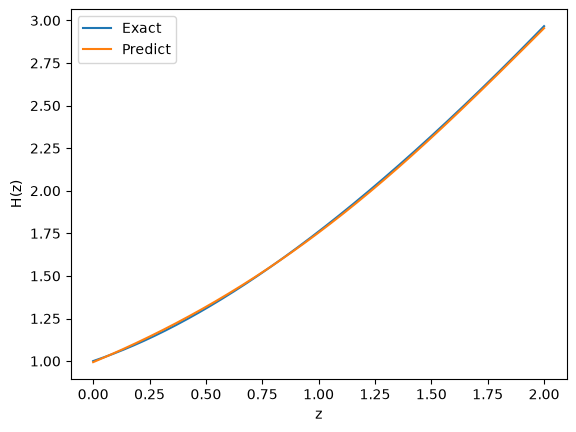

In [10]:
z_test = torch.linspace(0,2,1000).reshape(-1,1)
with torch.no_grad():
    H_pred = model_pinn(z_test)
plt.plot(z_test.numpy(), H_true.numpy(), label='Exact')
plt.plot(z_test.numpy(), H_pred.numpy(), label='Predict')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.legend()


- In this case, in addition to learning the function $H(z)$, the model also treats $\Omega_m$ as a learnable parameter. Therefore, PINNs can be used not only for function approximation but also for inference of cosmological parameters.

- This formulation provides a physics-based alternative to purely data-driven neural networks and enables an investigation of how physical constraints influence the reconstruction of the cosmic expansion history.

  <br><br>

### PINN Performance under Different Noisy Levels

In [11]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)
omega_m = 0.3
H_true =  torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std * torch.randn_like(H_true)
H_obs = H_true + noise
H_true = H_true.detach()
H_obs = H_obs.detach()

class ΛCDM_pinn_noise(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

model_pinn_noise = ΛCDM_pinn_noise()
optimizer_pinn_noise = torch.optim.Adam(model_pinn_noise.parameters(), lr =0.01)
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 2

for epoch in range(1000):
    H_pred = model_pinn_noise(z)
    dH_dz = torch.autograd.grad(
        outputs = H_pred,
        inputs = z,
        create_graph=True,
        grad_outputs=torch.ones_like(H_pred))[0]
    residual = 2 * H_pred * dH_dz - 3 * model_pinn_noise.omega_m2 * (1+z)**2 
    loss_r = torch.mean(residual**2)
    H0_pred = model_pinn_noise(z0)
    loss_ic = torch.mean((H0_pred-H0)**2)
    loss_data = torch.mean((H_pred - H_obs)**2)
    loss_pinn_noise = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
    optimizer_pinn_noise.zero_grad()
    loss_pinn_noise.backward()
    optimizer_pinn_noise.step()
    if epoch %200 == 0:
         print(
        epoch,
        "total =", loss_pinn_noise.item(),
        "L_r =", loss_r.item(),
        "L_ic =", loss_ic.item(),
        "L_data =", loss_data.item())
    
    
        

0 total = 64.45907592773438 L_r = 52.49851989746094 L_ic = 1.1809697151184082 L_data = 5.389794826507568
200 total = 0.7329722046852112 L_r = 0.15633492171764374 L_ic = 0.09372210502624512 L_data = 0.24145758152008057
400 total = 0.15627771615982056 L_r = 0.026209987699985504 L_ic = 0.016950277611613274 L_data = 0.056558720767498016
600 total = 0.028056982904672623 L_r = 0.009748480282723904 L_ic = 0.0009482205496169627 L_data = 0.008680140599608421
800 total = 0.0071738101541996 L_r = 0.0013881642371416092 L_ic = 4.4960834202356637e-05 L_data = 0.0028703424613922834


In [12]:
omega_m_est = model_pinn_noise.omega_m2.item()

print("True Omega_m =", omega_m)
print("Estimated Omega_m =", omega_m_est)
print(
    "Absolute error =",
    abs(omega_m_est - omega_m)
)

True Omega_m = 0.3
Estimated Omega_m = 0.2987107038497925
Absolute error = 0.0012892961502075084


In [13]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)

class ΛCDM_pinn_noise2(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

omega_m = 0.3
H_true =  torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m)).detach()
noise_levels = [0.0, 0.02, 0.05, 0.10]
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 1

for noise_std in noise_levels:
    noise = noise_std * torch.randn_like (H_true)
    H_obs = H_true + noise
    model_pinn_noise2 = ΛCDM_pinn_noise2()
    optimizer_pinn_noise2 = torch.optim.Adam(model_pinn_noise2.parameters(), lr =0.01)
    for epoch in range(1000):
        H_pred = model_pinn_noise2(z)
        dH_dz = torch.autograd.grad(
            outputs = H_pred,
            inputs = z,
            create_graph=True,
            grad_outputs=torch.ones_like(H_pred))[0]
        residual = 2 * H_pred * dH_dz - 3 * model_pinn_noise2.omega_m2 * (1+z)**2 
        loss_r = torch.mean(residual**2)
        H0_pred = model_pinn_noise2(z0)
        loss_ic = torch.mean((H0_pred-H0)**2)
        loss_data = torch.mean((H_pred - H_obs)**2)
        loss_pinn_noise2 = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
        optimizer_pinn_noise2.zero_grad()
        loss_pinn_noise2.backward()
        optimizer_pinn_noise2.step()
        if epoch %200 == 0:
             print(
            epoch,
            "total =", loss_pinn_noise2.item(),
            "L_r =", loss_r.item(),
            "L_ic =", loss_ic.item(),
            "L_data =", loss_data.item())  
    print( f"Noise = {noise_std*100:.0f}%  "
           f"Omega_m_true={omega_m:.1f} "
           f"Omega_m = {model_pinn_noise2.omega_m2.item():.4f}")
    print("-" * 60)
    
    

0 total = 59.05305480957031 L_r = 52.49851989746094 L_ic = 1.1809697151184082 L_data = 5.37356424331665
200 total = 0.5852969884872437 L_r = 0.06868188828229904 L_ic = 0.09839450567960739 L_data = 0.4182206094264984
400 total = 0.3684394657611847 L_r = 0.12787382304668427 L_ic = 0.020597681403160095 L_data = 0.21996796131134033
600 total = 0.079454705119133 L_r = 0.014956286177039146 L_ic = 0.006523063872009516 L_data = 0.05797535926103592
800 total = 0.01797853410243988 L_r = 0.007608570624142885 L_ic = 0.0004975720657967031 L_data = 0.009872392751276493
Noise = 0%  Omega_m_true=0.3 Omega_m = 0.2824
------------------------------------------------------------
0 total = 65.2657470703125 L_r = 55.23374938964844 L_ic = 2.950042724609375 L_data = 7.081953048706055
200 total = 0.2372233271598816 L_r = 0.0790552943944931 L_ic = 0.012446455657482147 L_data = 0.14572158455848694
400 total = 0.09549283236265182 L_r = 0.015982884913682938 L_ic = 0.00882784090936184 L_data = 0.0706821084022522
6

- To investigate the sensitivity of the PINN model to observational uncertaintiest, the model is evaluated under several noise levels: 0%, 2%, 5%and 10% .
- For each noise level, Gaussian noise is added to the theoretical ${\Lambda} CDM$ expansion history, and a Physics-Informed Neural Network (PINN) is independently initialized and trained. To ensure consistency and facilitate a fair comparison, the same network architecture and optimization settings are used across all experiments.

- The inferred value of $\Omega_m $ is then compared with its true value, $\Omega_m = 0.3$. This experiment is designed to investigate the impact of increasing observational noise on the reconstruction of the \(H(z)\) function and the accuracy of cosmological parameter inference.

- In particular, comparing the noise-free and noisy cases provides a controlled test of the robustness and stability of the proposed physics-informed approach.

<br><br>

### comparision: NN vs PINN

In [14]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)

omega_m = 0.3
class ΛCDM_nn_noise(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z
model_nn_compare = ΛCDM_nn_noise()
optimizer_nn_compare = torch.optim.Adam(model_nn_compare.parameters(), lr=0.01)
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std *torch.randn_like(H_true)
H_obs = H_true + noise

for epoch in range(1000):
    H_pred_nn = model_nn_compare(z)
    loss_data = torch.mean((H_pred_nn - H_obs)**2)
    optimizer_nn_compare.zero_grad()
    loss_data.backward()
    optimizer_nn_compare.step()
    if epoch %100 ==0:
        print(epoch, loss_data.item())
        

0 2.3666396141052246
100 0.016311433166265488
200 0.011481515131890774
300 0.00841858796775341
400 0.006199133116751909
500 0.004470651503652334
600 0.0032670816872268915
700 0.0026609033811837435
800 0.002458080416545272
900 0.0024101787712424994


In [15]:
with torch.no_grad():
    H_pred_nn =  model_nn_compare(z)
    mse_nn_obs = torch.mean((H_pred_nn-H_obs)**2)
    mse_nn_true = torch.mean((H_pred_nn - H_true)**2)

print(f"NN MSE vs observed data: {mse_nn_obs.item()} " , "\n"
      f"NN MSE vs true solution: {mse_nn_true.item()} " )

NN MSE vs observed data: 0.0024001130368560553  
NN MSE vs true solution: 3.739321982720867e-05 


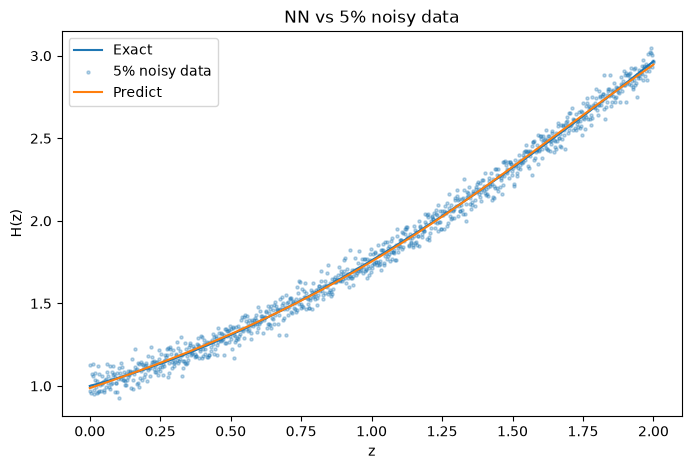

In [16]:
plt.figure(figsize=(8,5))

plt.plot (z.detach(), H_true.detach(), label = 'Exact')

plt.scatter (z.detach(), H_obs.detach(), s = 5 , alpha = 0.3, label = '5% noisy data')

plt.plot (z.detach(), H_pred_nn.detach(), label = 'Predict')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.title('NN vs 5% noisy data')
plt.legend()

plt.show()

In [17]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)
omega_m = 0.3
H_true =  torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std * torch.randn_like(H_true)
H_obs = H_true + noise
H_true = H_true.detach()
H_obs = H_obs.detach()

class ΛCDM_pinn_compare(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

model_pinn_compare = ΛCDM_pinn_compare()
optimizer_pinn_compare = torch.optim.Adam(model_pinn_compare.parameters(), lr =0.01)
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 2

for epoch in range(1000):
    H_pred_pinn = model_pinn_compare(z)
    dH_dz = torch.autograd.grad(
        outputs = H_pred_pinn,
        inputs = z,
        create_graph=True,
        grad_outputs=torch.ones_like(H_pred_pinn))[0]
    residual = 2 * H_pred_pinn * dH_dz - 3 * model_pinn_compare.omega_m2 * (1+z)**2 
    loss_r = torch.mean(residual**2)
    H0_pred_pinn = model_pinn_compare(z0)
    loss_ic = torch.mean((H0_pred_pinn-H0)**2)
    loss_data = torch.mean((H_pred_pinn - H_obs)**2)
    loss_pinn = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
    optimizer_pinn_compare.zero_grad()
    loss_pinn.backward()
    optimizer_pinn_compare.step()
    if epoch %200 == 0:
         print( epoch, loss_pinn.item())
    

0 64.45907592773438
200 0.7329722046852112
400 0.15627771615982056
600 0.028056982904672623
800 0.0071738101541996


In [18]:
with torch.no_grad():
    H_pred_pinn = model_pinn_compare(z)
    mse_pinn_obs = torch.mean((H_pred_pinn - H_obs)**2)
    mse_pinn_true = torch.mean((H_pred_pinn - H_true)**2)

print('PINN MSE vs observed data:', mse_pinn_obs.item())
print('PINN MSE vs true solution:' , mse_pinn_true.item())
    

PINN MSE vs observed data: 0.0024190146941691637
PINN MSE vs true solution: 7.377519978035707e-06


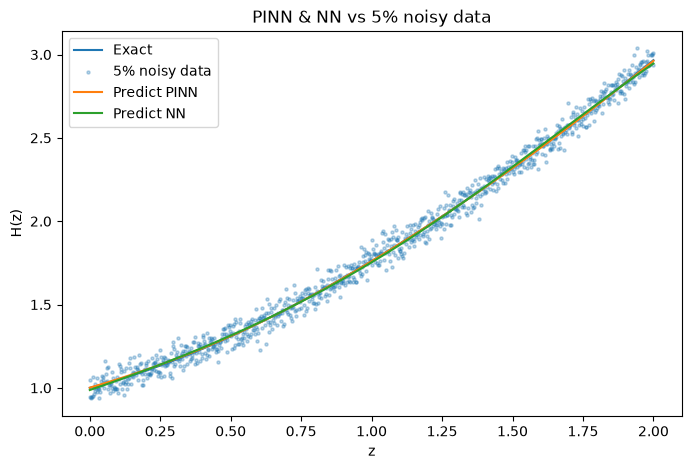

In [19]:
plt.figure(figsize=(8,5))
plt.plot (z.detach(), H_true.detach(), label = 'Exact')

plt.scatter (z.detach(), H_obs.detach(), s = 5 , alpha = 0.3, label = '5% noisy data')

plt.plot (z.detach(), H_pred_pinn.detach(), label = 'Predict PINN')

plt.plot (z.detach(), H_pred_nn.detach(), label = 'Predict NN')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.title('PINN & NN vs 5% noisy data')
plt.legend()

plt.show()

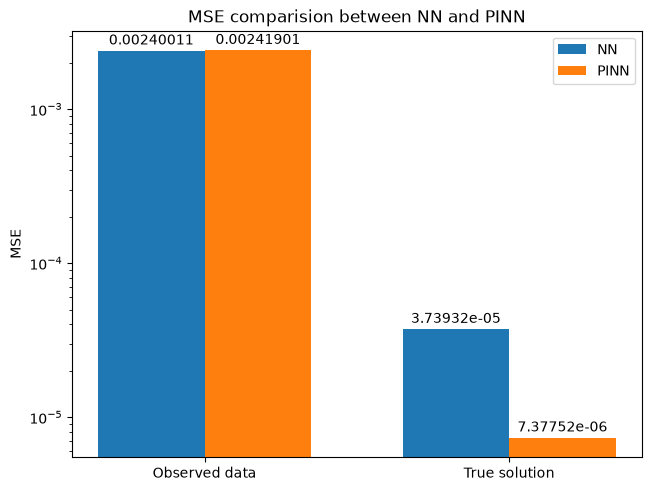

In [31]:
metrics = ('Observed data', 'True solution')
loss = {
    'NN': [mse_nn_obs.item(), mse_nn_true.item()],
    'PINN': [mse_pinn_obs.item(), mse_pinn_true.item()]
}

x = np.arange(len(metrics)) 
width = 0.35 
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for model, values in loss.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, values, width, label=model)
    ax.bar_label(rects, padding=2)
    multiplier += 1

ax.set_ylabel('MSE')
ax.set_title('MSE comparision between NN and PINN')
ax.set_xticks(x + width/2, metrics)
ax.legend()
ax.set_yscale('log')
plt.show()

In [41]:
nn_mse = mse_nn_true.item()
pinn_mse =  mse_pinn_true.item()
print (nn_mse/pinn_mse)

5.068535217598253


- Although a standard neural network achieves a slightly lower MSE (Mean Squared Error) relative to the noisy observations, the PINN model yields a significantly lower MSE when compared to the true, underlying ΛCDM solution. Specifically, compared to a purely data-driven neural network, the PINN model reduces the error relative to the true solution by approximately 80%. This result demonstrates the advantage of incorporating the governing physical equation into the learning process: the physical constraint enables the PINN to avoid fitting the random fluctuations present in the noisy observations and, instead, recover a solution that is more consistent with the underlying physical model.
  
- This comparison suggests that physics-informed learning can improve the recovery of the underlying physical signal even when it does not minimize the observational-data error.




### Real Cosmic Chronometers H(z) Data

### Uncertainty_Weighted Training

### Cosmological Parameter Inference from Real Data